<a href="https://colab.research.google.com/github/Magdalene-Olivia-Govender/Python-Project---Exchange-Rate-and-Oil-Price-Joint-Shock-Analysis/blob/main/SA_Inflation_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving SA_Inflation_Python_Project_2.csv to SA_Inflation_Python_Project_2 (1).csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

df.head()

,date,brent_crude,zar_usd,headline_cpi_yoy,food_cpi_yoy,core_cpi_yoy
0,2015-09-01,1.75,-0.78,4.53,4.4,5.4
1,2015-10-01,1.40,4.60,4.69,4.8,5.3
2,2015-11-01,-7.77,5.74,4.85,4.7,5.1
3,2015-12-01,-14.59,9.73,5.02,5.8,5.1
4,2016-01-01,-18.84,-3.75,6.16,7.0,5.5


In [ ]:
# Load and Validate Data Set
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats

# Load your file
df = pd.read_csv("SA_Inflation_Python_Project_2.csv")

# Standardize column names to lowercase to avoid casing errors
df.columns = df.columns.str.lower()

# Parse dates and sort chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")

# Required variables for this analysis
required = [
    "brent_crude",
    "zar_usd",
    "headline_cpi_yoy",
    "food_cpi_yoy",
    "core_cpi_yoy"
]

missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Retain the required columns and convert numeric fields
df = df[required].copy()

numeric_cols = required.copy()
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Ensure one observation per calendar month using the DatetimeIndex
df["month"] = df.index.to_period("M")

if df["month"].duplicated().any():
    raise ValueError(
        "Duplicate months found. Resolve these before modelling."
    )

# Check for missing months
expected_months = pd.period_range(
    df["month"].min(),
    df["month"].max(),
    freq="M"
)

actual_months = pd.PeriodIndex(df["month"])

missing_months = expected_months.difference(actual_months)
print("Missing calendar months:", list(missing_months))
print("\nMissing values:")
print(df[numeric_cols].isna().sum())

# Check the time span and sample size
print("\nSample:", df["month"].min(), "to", df["month"].max())
print("Rows:", len(df))

# Show summary statistics
print(df[numeric_cols].describe().T)

Missing calendar months: []

Missing values:
brent_crude         0
zar_usd             0
headline_cpi_yoy    0
food_cpi_yoy        0
core_cpi_yoy        0
dtype: int64

Sample: 2015-09 to 2026-08
Rows: 132
                  count      mean        std    min     25%    50%     75%  \
brent_crude       132.0  1.139924  11.547828 -43.07 -5.1475  1.815  6.7900   
zar_usd           132.0  0.186667   3.371160  -7.45 -1.9825 -0.510  2.1150   
headline_cpi_yoy  132.0  4.804394   1.324319   1.93  3.7950  4.740  5.6075   
food_cpi_yoy      132.0  6.110606   3.119583   0.90  3.9000  5.200  7.6250   
core_cpi_yoy      132.0  4.184091   0.819777   2.50  3.4000  4.200  4.8000   

                    max  
brent_crude       57.82  
zar_usd           11.57  
headline_cpi_yoy   7.81  
food_cpi_yoy      14.00  
core_cpi_yoy       5.90  


In [ ]:
# Verify the direction and units of each shock
print(
    df[["brent_crude", "zar_usd", "headline_cpi_yoy"]]
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
)

print(
    df[["brent_crude", "zar_usd", "headline_cpi_yoy"]]
    .corr()
)

       brent_crude     zar_usd  headline_cpi_yoy
count   132.000000  132.000000        132.000000
mean      1.139924    0.186667          4.804394
std      11.547828    3.371160          1.324319
min     -43.070000   -7.450000          1.930000
5%      -12.403500   -4.257000          2.880000
25%      -5.147500   -1.982500          3.795000
50%       1.815000   -0.510000          4.740000
75%       6.790000    2.115000          5.607500
95%      16.109500    5.915500          7.145000
max      57.820000   11.570000          7.810000
                  brent_crude   zar_usd  headline_cpi_yoy
brent_crude          1.000000 -0.199172         -0.167144
zar_usd             -0.199172  1.000000          0.087567
headline_cpi_yoy    -0.167144  0.087567          1.000000


In [ ]:
#Construct the oil and rand shock variables A one-unit shock represents a one-standard-deviation movement.
df["oil_z"] = (
    df["brent_crude"] - df["brent_crude"].mean()
) / df["brent_crude"].std(ddof=1)

df["zar_z"] = (
    df["zar_usd"] - df["zar_usd"].mean()
) / df["zar_usd"].std(ddof=1)

# Interaction term = observed shock proxies
df["oil_x_zar"] = df["oil_z"] * df["zar_z"]

print(df[["oil_z", "zar_z", "oil_x_zar"]].describe())

# oil_z: the oil-price association when the exchange-rate shock is at its sample mean.
# zar_z: the exchange-rate association when the oil shock is at its sample mean.
# oil_x_zar: whether the combined response differs from the sum of the individual responses.
# Shocks are standardised around their means, “zero shock” means the sample-average shock, not necessarily zero change in the original series.

              oil_z         zar_z   oil_x_zar
count  1.320000e+02  1.320000e+02  132.000000
mean   2.186803e-17  1.345725e-17   -0.197663
std    1.000000e+00  1.000000e+00    1.512373
min   -3.828419e+00 -2.265293e+00  -12.330837
25%   -5.444681e-01 -6.434481e-01   -0.195447
50%    5.845911e-02 -2.066549e-01   -0.014912
75%    4.892760e-01  5.720088e-01    0.258178
max    4.908289e+00  3.376681e+00    2.846667


In [ ]:
# Test for the order of integration - with a constant
# and deterministic linear time trend.
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss

# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

# Safely load the dataset to guarantee 'date' exists as a column
df = pd.read_csv("SA_Inflation_Python_Project_2.csv")

# Standardize column names to lowercase to avoid casing errors
df.columns = df.columns.str.lower()

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Continuous variables relevant to the research
variables_to_test = [
   "brent_crude",
    "zar_usd",
    "headline_cpi_yoy",
    "food_cpi_yoy",
    "core_cpi_yoy"
]

# Keep only variables that exist in the dataset
variables_to_test = [
    col for col in variables_to_test
    if col in df.columns
]


# --------------------------------------------------
# 2. Function to run ADF and KPSS tests
# --------------------------------------------------

def integration_tests(series, variable_name, stage):
    # Remove missing and infinite values
    series = series.replace([np.inf, -np.inf], np.nan).dropna()

    # Avoid running tests on very short series
    if len(series) < 20:
        return {
            "Variable": variable_name,
            "Stage": stage,
            "N": len(series),
            "ADF Statistic": np.nan,
            "ADF p-value": np.nan,
            "KPSS Statistic": np.nan,
            "KPSS p-value": np.nan
        }

    # ADF:
    # Null hypothesis = unit root / non-stationarity
    try:
        adf_result = adfuller(
            series,
            regression="ct",
            autolag="AIC"
        )
        adf_stat, adf_p = adf_result[0], adf_result[1]
    except Exception:
        adf_stat, adf_p = np.nan, np.nan

    # KPSS:
    # Null hypothesis = stationarity around a constant
    try:
        kpss_result = kpss(
            series,
            regression="ct",
            nlags="auto"
        )
        kpss_stat, kpss_p = kpss_result[0], kpss_result[1]
    except (OverflowError, ZeroDivisionError, ValueError):
        # Fallback to a fixed lag selection if auto-lag calculation fails
        try:
            kpss_result = kpss(
                series,
                regression="ct",
                nlags="legacy"
            )
            kpss_stat, kpss_p = kpss_result[0], kpss_result[1]
        except Exception:
            kpss_stat, kpss_p = np.nan, np.nan

    return {
        "Variable": variable_name,
        "Stage": stage,
        "N": len(series),
        "ADF Statistic": adf_stat,
        "ADF p-value": adf_p,
        "KPSS Statistic": kpss_stat,
        "KPSS p-value": kpss_p
    }


# --------------------------------------------------
# 3. Test variables at levels and first differences
# --------------------------------------------------

results = []

for variable in variables_to_test:
    series = df[variable]

    # Test at level
    level_result = integration_tests(
        series,
        variable,
        "Level"
    )
    results.append(level_result)

    # First difference
    first_difference = series.diff()

    # Test at first difference
    difference_result = integration_tests(
        first_difference,
        variable,
        "First Difference"
    )
    results.append(difference_result)


# --------------------------------------------------
# 4. Display results
# --------------------------------------------------

integration_results = pd.DataFrame(results)

print(
    integration_results.round(4).to_string(index=False)
)

        Variable            Stage   N  ADF Statistic  ADF p-value  KPSS Statistic  KPSS p-value
     brent_crude            Level 132        -8.2438       0.0000          0.0320        0.1000
     brent_crude First Difference 131        -7.9553       0.0000          0.1313        0.0771
         zar_usd            Level 132        -9.3797       0.0000          0.0542        0.1000
         zar_usd First Difference 131        -7.4753       0.0000          0.0767        0.1000
headline_cpi_yoy            Level 132        -2.5137       0.3212          0.1561        0.0416
headline_cpi_yoy First Difference 131        -3.0317       0.1234          0.0536        0.1000
    food_cpi_yoy            Level 132        -1.4758       0.8373          0.1704        0.0296
    food_cpi_yoy First Difference 131        -4.5958       0.0010          0.0815        0.1000
    core_cpi_yoy            Level 132        -1.7653       0.7212          0.2134        0.0110
    core_cpi_yoy First Difference 131   

/tmp/ipykernel_1776/1714259624.py:59: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_1776/1714259624.py:71: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_1776/1714259624.py:71: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now

In [ ]:
# ADF and KPSS lag for unit root and stationarity reliability testing

# ============================================================
# ADF AND KPSS STATIONARITY SENSITIVITY ANALYSIS
# South African Inflation and Monetary Policy Research
# ============================================================

import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss

# ------------------------------------------------------------
# 1. IMPORT AND PREPARE DATA
# ------------------------------------------------------------

df = pd.read_csv("SA_Inflation_Python_Project_2.csv")

df.columns = df.columns.str.lower().str.strip()

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = (
    df.dropna(subset=["date"])
      .sort_values("date")
      .reset_index(drop=True)
)

# Variables to test
variables_to_test = [
    "brent_crude",
    "zar_usd",
    "headline_cpi_yoy",
    "food_cpi_yoy",
    "core_cpi_yoy"
]

# Corrected variable selection
variables = [
    v for v in variables_to_test
    if v in df.columns
]

missing_variables = [
    v for v in variables_to_test
    if v not in df.columns
]

if missing_variables:
    print("WARNING - Variables not found:", missing_variables)

if not variables:
    raise ValueError("None of the specified variables were found.")

# ------------------------------------------------------------
# 2. DEFINE TEST SPECIFICATIONS
# ------------------------------------------------------------

# ADF deterministic specifications
adf_regressions = ["c", "ct"]

# ADF lag-selection methods
adf_autolag_methods = ["AIC", "BIC"]

# Fixed ADF lag specifications
fixed_adf_lags = [1, 3, 6, 12]

# KPSS deterministic specifications
kpss_regressions = ["c", "ct"]

# KPSS bandwidth specifications
kpss_bandwidths = ["auto", 3, 6, 12]

# ------------------------------------------------------------
# 3. SET ADF MAXIMUM LAG SEARCH
# ------------------------------------------------------------

def calculate_max_adf_lags(series):
    n = len(series)
    # Schwert-type maximum lag rule
    max_lags = int(np.floor(12 * (n / 100) ** 0.25))
    # Ensure the lag search is feasible
    return min(max_lags, max(0, n // 2 - 2))


# ------------------------------------------------------------
# 4. RUN ADF TESTS
# ------------------------------------------------------------

adf_results = []

for variable in variables:
    series = df[variable].dropna().astype(float)

    # Test both level and first difference
    transformations = {
        "Level": series,
        "First Difference": series.diff().dropna()
    }

    for transformation, data in transformations.items():
        if len(data) < 30:
            print(
                f"Skipping {variable} - {transformation}: "
                "insufficient observations."
            )
            continue

        max_adf_lags = calculate_max_adf_lags(data)

        # ADF with AIC and BIC lag selection
        for regression in adf_regressions:
            for method in adf_autolag_methods:
                try:
                    result = adfuller(
                        data,
                        maxlag=max_adf_lags,
                        regression=regression,
                        autolag=method
                    )
                    adf_results.append({
                        "Variable": variable,
                        "Transformation": transformation,
                        "Regression": regression,
                        "Lag Method": method,
                        "Selected Lag": result[2],
                        "ADF Statistic": result[0],
                        "P-value": result[1],
                        "Critical Value 1%": result[4]["1%"],
                        "Critical Value 5%": result[4]["5%"],
                        "Critical Value 10%": result[4]["10%"],
                        "Observations": result[3]
                    })
                except Exception as e:
                    print(
                        f"ADF error: {variable}, "
                        f"{transformation}, {regression}, "
                        f"{method}: {e}"
                    )

        # ADF with fixed lag specifications
        for regression in adf_regressions:
            for lag in fixed_adf_lags:
                if lag > max_adf_lags:
                    continue
                try:
                    result = adfuller(
                        data,
                        maxlag=lag,
                        regression=regression,
                        autolag=None
                    )
                    adf_results.append({
                        "Variable": variable,
                        "Transformation": transformation,
                        "Regression": regression,
                        "Lag Method": "Fixed",
                        "Selected Lag": lag,
                        "ADF Statistic": result[0],
                        "P-value": result[1],
                        "Critical Value 1%": result[4]["1%"],
                        "Critical Value 5%": result[4]["5%"],
                        "Critical Value 10%": result[4]["10%"],
                        "Observations": result[3]
                    })
                except Exception as e:
                    print(
                        f"ADF error: {variable}, "
                        f"{transformation}, {regression}, "
                        f"fixed lag {lag}: {e}"
                    )


# ------------------------------------------------------------
# 5. RUN KPSS TESTS
# ------------------------------------------------------------

kpss_results = []

for variable in variables:
    series = df[variable].dropna().astype(float)

    transformations = {
        "Level": series,
        "First Difference": series.diff().dropna()
    }

    for transformation, data in transformations.items():
        if len(data) < 30:
            continue

        for regression in kpss_regressions:
            for bandwidth in kpss_bandwidths:
                try:
                    result = kpss(
                        data,
                        regression=regression,
                        nlags=bandwidth
                    )
                    kpss_results.append({
                        "Variable": variable,
                        "Transformation": transformation,
                        "Regression": regression,
                        "Bandwidth": bandwidth,
                        "KPSS Statistic": result[0],
                        "P-value": result[1],
                        "Critical Value 1%": result[3]["1%"],
                        "Critical Value 5%": result[3]["5%"],
                        "Critical Value 10%": result[3]["10%"],
                        "Observations": len(data)
                    })
                except Exception as e:
                    print(
                        f"KPSS error: {variable}, "
                        f"{transformation}, {regression}, "
                        f"bandwidth {bandwidth}: {e}"
                    )


# ------------------------------------------------------------
# 6. CONVERT RESULTS INTO DATAFRAMES
# ------------------------------------------------------------

adf_df = pd.DataFrame(adf_results)
kpss_df = pd.DataFrame(kpss_results)


# ------------------------------------------------------------
# 7. ADD INTERPRETATION FLAGS
# ------------------------------------------------------------

if not adf_df.empty:
    adf_df["5% Decision"] = np.where(
        adf_df["P-value"] < 0.05,
        "Reject unit-root null",
        "Fail to reject unit-root null"
    )

if not kpss_df.empty:
    kpss_df["5% Decision"] = np.where(
        kpss_df["P-value"] < 0.05,
        "Reject stationarity null",
        "Fail to reject stationarity null"
    )


# ------------------------------------------------------------
# 8. EXPORT RESULTS
# ------------------------------------------------------------

with pd.ExcelWriter(
    "SA_Stationarity_Sensitivity_Results.xlsx"
) as writer:
    adf_df.to_excel(
        writer,
        sheet_name="ADF Results",
        index=False
    )
    kpss_df.to_excel(
        writer,
        sheet_name="KPSS Results",
        index=False
    )


# ------------------------------------------------------------
# 9. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nADF TEST RESULTS")
print(adf_df.head(20).to_string(index=False))

print("\nKPSS TEST RESULTS")
print(kpss_df.head(20).to_string(index=False))

print(
    "\nAnalysis complete. Results exported to "
    "SA_Stationarity_Sensitivity_Results.xlsx"
)

/tmp/ipykernel_1776/1694234480.py:114: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_1776/1694234480.py:114: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_1776/1694234480.py:114: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.1


ADF TEST RESULTS
   Variable   Transformation Regression Lag Method  Selected Lag  ADF Statistic      P-value  Critical Value 1%  Critical Value 5%  Critical Value 10%  Observations                   5% Decision
brent_crude            Level          c        AIC             2      -8.274758 4.688973e-13          -3.482088          -2.884219           -2.578864           129         Reject unit-root null
brent_crude            Level          c        BIC             1      -9.073904 4.229611e-15          -3.481682          -2.884042           -2.578770           130         Reject unit-root null
brent_crude            Level         ct        AIC             2      -8.243804 1.952783e-11          -4.030720          -3.445088           -3.147340           129         Reject unit-root null
brent_crude            Level         ct        BIC             1      -9.038578 2.969608e-13          -4.030152          -3.444818           -3.147182           130         Reject unit-root null
brent_c

In [ ]:
# Optimal lag length - Inflation and shock variables
from statsmodels.tsa.api import VAR

# --------------------------------------------------
# 1. Select variables for dynamic lag selection
# --------------------------------------------------

lag_variables = [
    "headline_cpi_yoy",
    "brent_crude",
    "zar_usd"
]

lag_df = df[lag_variables].dropna()

# --------------------------------------------------
# 2. Estimate VAR and select lag length
# --------------------------------------------------

var_model = VAR(lag_df)

lag_selection = var_model.select_order(maxlags=6)

print(lag_selection.summary())

# --------------------------------------------------
# 3. Extract selected lag lengths
# --------------------------------------------------

print("AIC selected lag:", lag_selection.aic)
print("BIC selected lag:", lag_selection.bic)
print("HQIC selected lag:", lag_selection.hqic)

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       7.787       7.855       2410.       7.815
1       5.256      5.526*       191.7      5.366*
2      5.224*       5.697      185.7*       5.416
3       5.270       5.946       194.7       5.545
4       5.327       6.205       206.3       5.684
5       5.332       6.412       207.7       5.771
6       5.366       6.650       215.6       5.888
-------------------------------------------------
AIC selected lag: 2
BIC selected lag: 1
HQIC selected lag: 1


In [ ]:
#Estimation of Local projection model

# ============================================================
# SOUTH AFRICAN INFLATION: LOCAL PROJECTIONS
# One-lag and two-lag control specifications
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. IMPORT AND PREPARE DATA
# ------------------------------------------------------------

df = pd.read_csv("SA_Inflation_Python_Project_2.csv")

df.columns = df.columns.str.lower().str.strip()

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = (
    df.dropna(subset=["date"])
      .sort_values("date")
      .drop_duplicates(subset=["date"])
      .reset_index(drop=True)
)

# Variables
outcome = "headline_cpi_yoy"

oil = "brent_crude"

exchange_rate = "zar_usd"

variables = [outcome, oil, exchange_rate]

# Confirm that all required variables exist
missing = [v for v in variables if v not in df.columns]

if missing:
    raise ValueError(f"Missing variables: {missing}")

# Ensure numerical data
for variable in variables:
    df[variable] = pd.to_numeric(
        df[variable], errors="coerce"
    )

# ------------------------------------------------------------
# 2. STANDARDISE THE OIL AND EXCHANGE-RATE VARIABLES
# ------------------------------------------------------------

# Standardisation makes the interaction coefficients
# easier to interpret in terms of one-standard-deviation
# movements in each explanatory variable.

df["oil_shock"] = (
    df[oil] - df[oil].mean()
) / df[oil].std()

df["fx_shock"] = (
    df[exchange_rate] - df[exchange_rate].mean()
) / df[exchange_rate].std()

# Interaction term
df["oil_fx_interaction"] = (
    df["oil_shock"] * df["fx_shock"]
)

# ------------------------------------------------------------
# 3. CREATE LAGGED CONTROL VARIABLES
# ------------------------------------------------------------

# Create lags 1 and 2 for all three original variables.

for variable in variables:

    for lag in [1, 2]:

        df[f"{variable}_lag{lag}"] = (
            df[variable].shift(lag)
        )

# ------------------------------------------------------------
# 4. DEFINE LOCAL PROJECTION HORIZONS
# ------------------------------------------------------------

horizons = [0, 1, 3, 6, 12]

# VAR selection suggests:
# Primary specification: 1 lag
# Robustness specification: 2 lags

lag_specifications = [1, 2]

results = []

# ------------------------------------------------------------
# 5. ESTIMATE LOCAL PROJECTIONS
# ------------------------------------------------------------

for p in lag_specifications:

    for h in horizons:

        # Dependent variable at t+h
        df["future_inflation"] = (
            df[outcome].shift(-h)
        )

        # Contemporaneous explanatory variables
        regressors = [
            "oil_shock",
            "fx_shock",
            "oil_fx_interaction"
        ]

        # Add lagged controls
        for variable in variables:

            for lag in range(1, p + 1):

                regressors.append(
                    f"{variable}_lag{lag}"
                )

        # Build estimation dataset
        model_data = df[
            ["future_inflation"] + regressors
        ].dropna()

        # Dependent and independent variables
        y = model_data["future_inflation"]

        X = sm.add_constant(
            model_data[regressors]
        )

        # HAC standard errors
        hac_lags = max(1, h + 1)

        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={
                "maxlags": hac_lags
            }
        )

        # Extract coefficients and confidence intervals
        for variable in [
            "oil_shock",
            "fx_shock",
            "oil_fx_interaction"
        ]:

            ci = model.conf_int().loc[variable]

            results.append({

                "Control Lags": p,

                "Horizon": h,

                "Variable": variable,

                "Coefficient": model.params[variable],

                "Standard Error": model.bse[variable],

                "P-value": model.pvalues[variable],

                "CI Lower": ci.iloc[0],

                "CI Upper": ci.iloc[1],

                "Observations": int(model.nobs),

                "R-squared": model.rsquared,

                "HAC Lags": hac_lags

            })

# ------------------------------------------------------------
# 6. EXPORT RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

with pd.ExcelWriter(
    "SA_Local_Projection_Results.xlsx"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="LP Coefficients",
        index=False
    )

    # Also export the dataset with its generated lags
    df.to_excel(
        writer,
        sheet_name="Lagged Dataset",
        index=False
    )

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nLOCAL PROJECTION RESULTS")

print(
    results_df.to_string(index=False)
)

print(
    "\nResults exported to "
    "SA_Local_Projection_Results.xlsx"
)



LOCAL PROJECTION RESULTS
 Control Lags  Horizon           Variable  Coefficient  Standard Error      P-value  CI Lower  CI Upper  Observations  R-squared  HAC Lags
            1        0          oil_shock    -0.009509        0.033713 7.779060e-01 -0.075586  0.056568           131   0.910272         1
            1        0           fx_shock     0.000165        0.038014 9.965305e-01 -0.074341  0.074672           131   0.910272         1
            1        0 oil_fx_interaction     0.046620        0.019207 1.521173e-02  0.008976  0.084264           131   0.910272         1
            1        1          oil_shock     0.203055        0.060161 7.375859e-04  0.085142  0.320967           130   0.809159         2
            1        1           fx_shock     0.074971        0.048541 1.224669e-01 -0.020167  0.170110           130   0.809159         2
            1        1 oil_fx_interaction     0.082635        0.028117 3.292496e-03  0.027528  0.137743           130   0.809159         2
 

In [ ]:
# Stationarity of oil shock/ zar shock / interaction term shock
stationarity_vars = [
     "oil_shock",
      "fx_shock",
      "oil_fx_interaction",
      "future_inflation"
]

def run_stationarity_tests(series):
    x = series.dropna().astype(float)

    adf_result = adfuller(x, regression="c", autolag="AIC")
    kpss_result = kpss(x, regression="c", nlags="auto")

    return {
        "ADF statistic": adf_result[0],
        "ADF p-value": adf_result[1],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
        "Observations": len(x)
    }

stationarity_results = pd.DataFrame({
    col: run_stationarity_tests(df[col])
    for col in stationarity_vars
}).T

display(stationarity_results.round(4))

/tmp/ipykernel_1776/998721151.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(x, regression="c", autolag="AIC")
/tmp/ipykernel_1776/998721151.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(x, regression="c", nlags="auto")
/tmp/ipykernel_1776/998721151.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to alway

,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Observations
oil_shock,-8.2748,0.0000,0.0344,0.1,132.0
fx_shock,-9.3927,0.0000,0.0739,0.1,132.0
oil_fx_interaction,-4.7250,0.0001,0.1403,0.1,132.0
future_inflation,-2.1143,0.2388,0.1860,0.1,120.0


In [ ]:
# Correlation Matrix and Heat Map

import pandas as pd

# Select the variables for correlation analysis
correlation_variables = [
      "oil_shock",
      "fx_shock",
      "oil_fx_interaction",
      "future_inflation"

]

# Create a dataset containing only these variables
correlation_df = df[correlation_variables].copy()

# Calculate Pearson correlation coefficients
correlation_matrix = correlation_df.corr(method="pearson")

# Display the results
print(correlation_matrix.round(3))


                    oil_shock  fx_shock  oil_fx_interaction  future_inflation
oil_shock               1.000    -0.199              -0.086             0.213
fx_shock               -0.199     1.000              -0.230             0.015
oil_fx_interaction     -0.086    -0.230               1.000             0.032
future_inflation        0.213     0.015               0.032             1.000


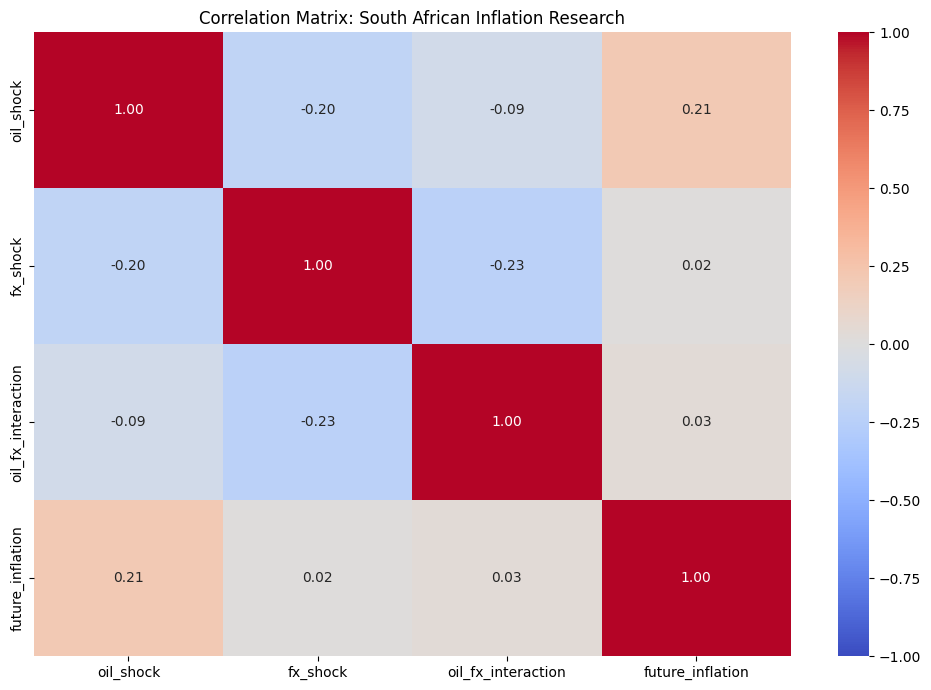

In [ ]:
# Heat Map
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix: South African Inflation Research")
plt.tight_layout()
plt.show()

In [ ]:
# Explanatory/local projection Model - Oil shock proxy + Rand shock Proxy + Interaction term
df["oil_shock_lag1"] = df["oil_shock"].shift(1)
df["fx_shock_lag1"] = df["fx_shock"].shift(1)
df["oil_fx_interaction_lag1"] = df['oil_fx_interaction'].shift(1)
df["future_inflation_lag1"] = df["future_inflation"].shift(1)

features = [
    "oil_shock_lag1",
    "fx_shock_lag1",
    "oil_fx_interaction_lag1",
    "future_inflation_lag1"
]

analysis_df = df[
    ["future_inflation"] + features
].dropna()

y = analysis_df["future_inflation"]
X = sm.add_constant(analysis_df[features])

model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       future_inflation   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                     292.6
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           5.86e-59
Time:                        10:05:16   Log-Likelihood:                -57.832
No. Observations:                 119   AIC:                             125.7
Df Residuals:                     114   BIC:                             139.6
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [ ]:
# Explanatory/local projection Model - Oil shock proxy + Rand shock Proxy + Interaction term

df["oil_fx_interaction"] = df['oil_fx_interaction']
df["brent_zar_core_lag1"] = df["brent_crude"].shift(1) + df["zar_usd"].shift(1) + df["core_cpi_yoy"].shift(1)

features = [
    "brent_crude",
    "zar_usd",
    "oil_fx_interaction",
    "brent_zar_cpi_lag1"
]

analysis_df = df[
    ["future_inflation"] + features
].dropna()

y = analysis_df["future_inflation"]
X = sm.add_constant(analysis_df[features])

model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       future_inflation   R-squared:                       0.060
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     3.465
Date:                Fri, 30 Oct 2026   Prob (F-statistic):             0.0104
Time:                        10:20:13   Log-Likelihood:                -198.80
No. Observations:                 119   AIC:                             407.6
Df Residuals:                     114   BIC:                             421.5
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  4.6173      0

In [ ]:
# Oil price shock only

import pandas as pd
import numpy as np

# Work on a copy and reset index to restore 'date' as a column
df_copy = df.copy()
if 'date' not in df_copy.columns:
    df_copy = df_copy.reset_index()

df_copy["date"] = pd.to_datetime(df_copy["date"])
df_copy = df_copy.sort_values("date").reset_index(drop=True)

# Use only positive oil-price changes to estimate the threshold
positive_oil_changes = df_copy.loc[
    df_copy["brent_crude"] > 0, "brent_crude"
].dropna()

oil_threshold = positive_oil_changes.quantile(0.65)

# Identify an oil shock
df_copy["oil_shock"] = (
    df_copy["brent_crude"] > oil_threshold
).astype("Int64")

# Avoid classifying the first missing percentage change as a non-shock
df_copy.loc[df_copy["brent_crude"].isna(), "oil_shock"] = pd.NA

# Count shock months
oil_shock_count = int(df_copy["oil_shock"].sum())

print(f"Oil shock threshold: {oil_threshold:.2f}% monthly increase")
print(f"Number of oil-shock months: {oil_shock_count}")
print(f"Total valid monthly observations: {df_copy['brent_crude'].notna().sum()}")

# Display the dates and changes associated with oil shocks
print(
    df_copy.loc[
        df_copy["oil_shock"] == 1,
        ["date", "brent_crude", "oil_shock"]
    ].to_string(index=False)
)

Oil shock threshold: 7.83% monthly increase
Number of oil-shock months: 26
Total valid monthly observations: 132
      date  brent_crude  oil_shock
2016-03-01        19.23          1
2016-04-01         7.96          1
2016-05-01        13.05          1
2016-12-01        18.19          1
2017-09-01         8.75          1
2017-11-01         9.34          1
2018-04-01         8.79          1
2018-09-01         8.49          1
2019-02-01         8.12          1
2019-04-01         7.88          1
2020-05-01        57.82          1
2020-06-01        35.48          1
2020-07-01         8.31          1
2020-12-01        16.98          1
2021-01-01         9.99          1
2021-02-01        13.29          1
2021-10-01        12.48          1
2022-01-01        16.06          1
2022-02-01        12.51          1
2022-03-01        16.17          1
2022-05-01         8.48          1
2022-06-01         8.54          1
2023-04-01         8.08          1
2023-09-01         8.61          1
2025-06-01  

In [ ]:
# Rand depreciation shock only
# Calculate monthly percentage change in ZAR per USD
# A positive change indicates rand depreciation

# Estimate the threshold using positive depreciation observations
positive_depreciation = df.loc[
    df["zar_usd"] > 0, "zar_usd"
].dropna()

zar_threshold = positive_depreciation.quantile(0.65)

# Identify a depreciation shock
df["zar_shock"] = (
    df["zar_usd"] > zar_threshold
).astype("Int64")

# Preserve missing values where the change cannot be calculated
df.loc[df["zar_usd"].isna(), "zar_shock"] = pd.NA

# Count shock months
zar_shock_count = int(df["zar_shock"].sum())

print(f"Rand depreciation threshold: {zar_threshold:.2f}% monthly depreciation")
print(f"Number of depreciation-shock months: {zar_shock_count}")
print(f"Total valid monthly observations: {df['zar_usd'].notna().sum()}")

# Display the shock dates safely by resetting the index temporarily
print(
    df.loc[df["zar_shock"] == 1, ["date", "zar_usd", "zar_shock"]]
    .reset_index()
    .to_string(index=False)
)

Rand depreciation threshold: 4.26% monthly depreciation
Number of depreciation-shock months: 19
Total valid monthly observations: 132
 index       date  zar_usd  zar_shock
     1 2015-10-01     4.60          1
     2 2015-11-01     5.74          1
     3 2015-12-01     9.73          1
     7 2016-04-01     4.99          1
    32 2018-05-01     6.13          1
    34 2018-07-01     5.14          1
    35 2018-08-01     4.85          1
    46 2019-07-01     7.82          1
    52 2020-01-01     4.30          1
    53 2020-02-01    10.91          1
    54 2020-03-01    11.57          1
    69 2021-06-01     4.40          1
    73 2021-10-01     4.44          1
    79 2022-04-01     6.15          1
    81 2022-06-01     6.78          1
    83 2022-08-01     5.20          1
    88 2023-01-01     4.72          1
    91 2023-04-01     4.89          1
   125 2026-02-01     4.72          1


In [ ]:
#Joint shock defined as 75th-percentile threshold among positive changes - disproportionate positive monthly change
positive_oil = df.loc[
    df["brent_crude"] > 0, "brent_crude"
]

positive_depreciation = df.loc[
    df["zar_usd"] > 0, "zar_usd"
]

oil_threshold = positive_oil.quantile(0.65)
fx_threshold = positive_depreciation.quantile(0.65)

df["joint_shock"] = (
    (df["brent_crude"] >= oil_threshold) &
    (df["zar_usd"] >= fx_threshold)
).astype(int)

print("Oil threshold:", oil_threshold)
print("Depreciation threshold:", fx_threshold)
print("Number of joint-shock months:", df["joint_shock"].sum())

Oil threshold: 7.825
Depreciation threshold: 4.261500000000001
Number of joint-shock months: 4


In [ ]:
#Inflation risk variables
TARGET_CHANGE_DATE = pd.Timestamp("2025-11-12")

df["inflation_target"] = np.where(
    pd.to_datetime(df.index) >= TARGET_CHANGE_DATE,
    3.0,   # Current point target
    4.5    # Midpoint of former 3–6% target range
)

df["target_gap"] = (
    df["core_cpi_yoy"] - df["inflation_target"]
)

df["absolute_target_gap"] = df["target_gap"].abs()

df[[
    "core_cpi_yoy",
    "inflation_target",
    "target_gap",
    "absolute_target_gap"
]].tail()

,core_cpi_yoy,inflation_target,target_gap,absolute_target_gap
127,3.6,4.5,-0.9,0.9
128,3.8,4.5,-0.7,0.7
129,4.1,4.5,-0.4,0.4
130,4.2,4.5,-0.3,0.3
131,4.1,4.5,-0.4,0.4


In [ ]:
# Comparing joint shock months with other months
comparison = (
    df.groupby("joint_shock")
      .agg(
          observations=("core_cpi_yoy", "count"),
          mean_inflation=("core_cpi_yoy", "mean"),
          mean_absolute_gap=("absolute_target_gap", "mean"),
          median_absolute_gap=("absolute_target_gap", "median")
      )
)

comparison.index = ["Other months", "Joint-shock months"]
print(comparison)

                    observations  mean_inflation  mean_absolute_gap  \
Other months                 128        4.171094           0.716406   
Joint-shock months             4        4.600000           0.800000   

                    median_absolute_gap  
Other months                       0.65  
Joint-shock months                 0.90  


In [ ]:
# Explanatory Baseline Model p=1 Future food CPI (h = 3)

# 1. Create future dependent variables
df["future_core_cpi"] = df["core_cpi_yoy"].shift(-3)
df["future_food_cpi"] = df["food_cpi_yoy"].shift(-3)

# 2. Create lagged inflation and shock variables
lagged_variables = [
    "zar_shock",
    "oil_shock",
    "joint_shock",
    "core_cpi_yoy",
    "food_cpi_yoy"
]

for variable in lagged_variables:
    df[f"{variable}_lag1"] = df[variable].shift(1)

# 3. Specify explanatory variables
features = [
    # Current shock variables
   # Current shock variables
    "oil_shock",
    "zar_shock",
    "joint_shock",

    # Lagged shock variables
    "zar_shock_lag1",
    "oil_shock_lag1",
    "joint_shock_lag1",

    # Lagged inflation controls
    "core_cpi_yoy_lag1",
    "food_cpi_yoy_lag1"
]

# 4. Prepare the analysis dataset
analysis_df = df[
    ["future_food_cpi"] + features
].dropna()

# 5. Define dependent and independent variables
y_p1 = analysis_df["future_food_cpi"]
X_p1 = sm.add_constant(analysis_df[features])

# 6. Estimate the LP regression with HAC standard errors
model_p1 = sm.OLS(y_p1, X_p1).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

# 7. Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        future_food_cpi   R-squared:                       0.666
Model:                            OLS   Adj. R-squared:                  0.643
Method:                 Least Squares   F-statistic:                     12.39
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.58e-13
Time:                        15:43:57   Log-Likelihood:                -258.27
No. Observations:                 128   AIC:                             534.5
Df Residuals:                     119   BIC:                             560.2
Df Model:                           8                                         
Covariance Type:                  HAC                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.6335      1.58

In [ ]:
# Explanatory Baseline Model - p=1 Future Core CPI (h = 3)

# 1. Create future dependent variables
df["future_core_cpi"] = df["core_cpi_yoy"].shift(-3)
df["future_food_cpi"] = df["food_cpi_yoy"].shift(-3)

# 2. Create lagged inflation and shock variables
lagged_variables = [
    "zar_shock",
    "oil_shock",
    "joint_shock",
    "core_cpi_yoy",
    "food_cpi_yoy"
]

for variable in lagged_variables:
    for lag in [1, 2]:
      df[f"{variable}_lag{lag}"] = df[variable].shift(lag)

# 3. Specify explanatory variables
features = [
    # Current shock variables
    "oil_shock",
    "zar_shock",
    "joint_shock",

    # Lagged shock variables
    "zar_shock_lag1",
    "oil_shock_lag1",
    "joint_shock_lag1",

    # Lagged inflation controls
    "core_cpi_yoy_lag1",
    "food_cpi_yoy_lag1"
]

# 4. Prepare the analysis dataset
analysis_df = df[
    ["future_core_cpi"] + features
].dropna()

# 5. Define dependent and independent variables
y_p1 = analysis_df["future_core_cpi"]
X_p1 = sm.add_constant(analysis_df[features])

# 6. Estimate the LP regression with HAC standard errors
model_p1 = sm.OLS(y_p1, X_p1).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

# 7. Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        future_food_cpi   R-squared:                       0.666
Model:                            OLS   Adj. R-squared:                  0.643
Method:                 Least Squares   F-statistic:                     12.39
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.58e-13
Time:                        15:44:37   Log-Likelihood:                -258.27
No. Observations:                 128   AIC:                             534.5
Df Residuals:                     119   BIC:                             560.2
Df Model:                           8                                         
Covariance Type:                  HAC                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.6335      1.58

In [ ]:
# Explanatory Model - Robustness Check p=2 future_food_cpi

# 1. Create future dependent variables
df["future_core_cpi"] = df["core_cpi_yoy"].shift(-3)
df["future_food_cpi"] = df["food_cpi_yoy"].shift(-3)

# 2. Create lagged inflation and shock variables
lagged_variables = [
    "zar_shock",
    "oil_shock",
    "joint_shock",
    "core_cpi_yoy",
    "food_cpi_yoy"
]

for variable in lagged_variables:
    for lag in [1, 2]:
        df[f"{variable}_lag{lag}"] = df[variable].shift(lag)

# 3. Specify explanatory variables
features = [
    # Current shock variables
    "oil_shock",
    "zar_shock",
    "joint_shock",

    # Lagged shock variables
    "zar_shock_lag1",
    "zar_shock_lag2",
    "oil_shock_lag1",
    "oil_shock_lag2",
    "joint_shock_lag1",
    "joint_shock_lag2",

    # Lagged inflation controls
    "core_cpi_yoy_lag1",
    "core_cpi_yoy_lag2",
    "food_cpi_yoy_lag1",
    "food_cpi_yoy_lag2"
]

# 4. Prepare the analysis dataset
analysis_df = df[
    ["future_food_cpi"] + features
].dropna()

# 5. Define dependent and independent variables
y_p2 = analysis_df["future_food_cpi"]
X_p2 = sm.add_constant(analysis_df[features])

# 6. Estimate the LP regression with HAC standard errors
model_p2 = sm.OLS(y_p2, X_p2).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

# 7. Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        future_core_cpi   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     24.55
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.85e-27
Time:                        15:47:12   Log-Likelihood:                -46.845
No. Observations:                 127   AIC:                             121.7
Df Residuals:                     113   BIC:                             161.5
Df Model:                          13                                         
Covariance Type:                  HAC                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.5912      0.25

In [ ]:
# Explanatory Model - Robustness Check p=2 future_core_cpi

# 1. Create future dependent variables
df["future_core_cpi"] = df["core_cpi_yoy"].shift(-3)
df["future_food_cpi"] = df["food_cpi_yoy"].shift(-3)

# 2. Create lagged inflation and shock variables
lagged_variables = [
    "zar_shock",
    "oil_shock",
    "joint_shock",
    "core_cpi_yoy",
    "food_cpi_yoy"
]

for variable in lagged_variables:
    for lag in [1, 2]:
        df[f"{variable}_lag{lag}"] = df[variable].shift(lag)

# 3. Specify explanatory variables
features = [
    # Current shock variables
    "oil_shock",
    "zar_shock",
    "joint_shock",

    # Lagged shock variables
    "zar_shock_lag1",
    "zar_shock_lag2",
    "oil_shock_lag1",
    "oil_shock_lag2",
    "joint_shock_lag1",
    "joint_shock_lag2",

    # Lagged inflation controls
    "core_cpi_yoy_lag1",
    "core_cpi_yoy_lag2",
    "food_cpi_yoy_lag1",
    "food_cpi_yoy_lag2"
]

# 4. Prepare the analysis dataset
analysis_df = df[
    ["future_core_cpi"] + features
].dropna()

# 5. Define dependent and independent variables
y_p2 = analysis_df["future_core_cpi"]
X_p2 = sm.add_constant(analysis_df[features])

# 6. Estimate the LP regression with HAC standard errors
model_p2 = sm.OLS(y_p2, X_p2).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

# 7. Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        future_core_cpi   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     24.55
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.85e-27
Time:                        15:47:22   Log-Likelihood:                -46.845
No. Observations:                 127   AIC:                             121.7
Df Residuals:                     113   BIC:                             161.5
Df Model:                          13                                         
Covariance Type:                  HAC                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.5912      0.25

In [ ]:
# Explanatory Model - Robustness Check p=2 future_core_cpi HAC Adjustment

# 1. Create future dependent variables
df["future_core_cpi"] = df["core_cpi_yoy"].shift(-3)
df["future_food_cpi"] = df["food_cpi_yoy"].shift(-3)

# 2. Create lagged inflation and shock variables
lagged_variables = [
    "zar_shock",
    "oil_shock",
    "joint_shock",
    "core_cpi_yoy",
    "food_cpi_yoy"
]

for variable in lagged_variables:
    for lag in [1, 2]:
        df[f"{variable}_lag{lag}"] = df[variable].shift(lag)

# 3. Specify explanatory variables
features = [
    # Current shock variables
    "oil_shock",
    "zar_shock",
    "joint_shock",

    # Lagged shock variables
    "zar_shock_lag1",
    "zar_shock_lag2",
    "oil_shock_lag1",
    "oil_shock_lag2",
    "joint_shock_lag1",
    "joint_shock_lag2",

    # Lagged inflation controls
    "core_cpi_yoy_lag1",
    "core_cpi_yoy_lag2",
    "food_cpi_yoy_lag1",
    "food_cpi_yoy_lag2"
]

# 4. Prepare the analysis dataset
analysis_df = df[
    ["future_core_cpi"] + features
].dropna()

# 5. Define dependent and independent variables
y_p2 = analysis_df["future_core_cpi"]
X_p2 = sm.add_constant(analysis_df[features])

# 6. Re-estimate the p=2 LP regression with different HAC bandwidths

model_p2_hac3 = sm.OLS(y_p2, X_p2).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 3}
)

model_p2_hac6 = sm.OLS(y_p2, X_p2).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

model_p2_hac12 = sm.OLS(y_p2, X_p2).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

# 7. Display the regression results

print("P2 MODEL - HAC MAXLAG 3")
print(model_p2_hac3.summary())

print("\nP2 MODEL - HAC MAXLAG 6")
print(model_p2_hac6.summary())

print("\nP2 MODEL - HAC MAXLAG 12")
print(model_p2_hac12.summary())


P2 MODEL - HAC MAXLAG 3
                            OLS Regression Results                            
Dep. Variable:        future_core_cpi   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     24.22
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.30e-27
Time:                        16:50:05   Log-Likelihood:                -46.845
No. Observations:                 127   AIC:                             121.7
Df Residuals:                     113   BIC:                             161.5
Df Model:                          13                                         
Covariance Type:                  HAC                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const         

In [ ]:
#Residual Analysis model_p1
#Extract residuals and fitted values

residuals_p1 = model_p1.resid
fitted_values_p1 = model_p1.fittedvalues

print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())
print("Number of observations:", len(residuals))

Residual mean: -8.741913579725643e-17
Residual standard deviation: 0.35129425019144134
Number of observations: 127


In [ ]:
#Residual Analysis model_p2
#Extract residuals and fitted values

residuals_p2 = model_p2.resid
fitted_values_p2 = model_p2.fittedvalues

print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())
print("Number of observations:", len(residuals))

Residual mean: -8.741913579725643e-17
Residual standard deviation: 0.35129425019144134
Number of observations: 127


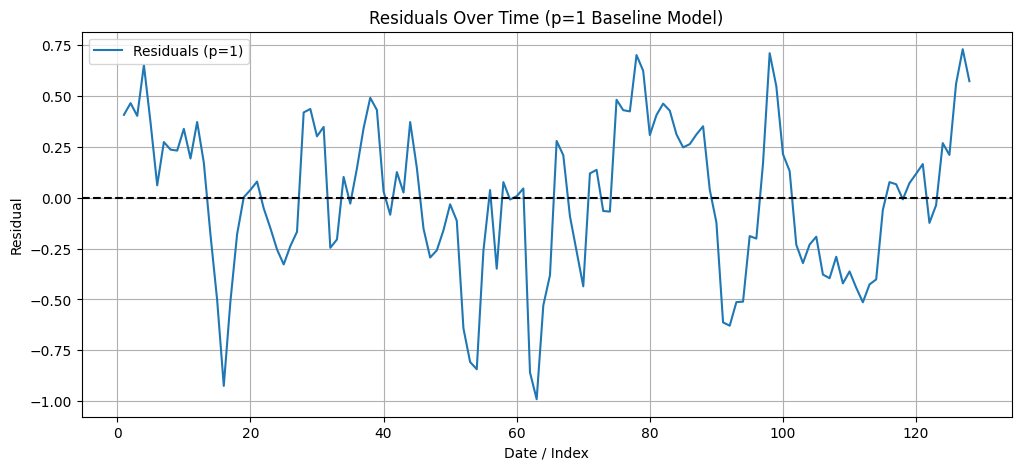

In [ ]:
#Plot residuals over time

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Safely align the x-axis by using the index corresponding to the p=1 dependent variable
plt.plot(
    y_p1.index,
    residuals_p1,
    label="Residuals (p=1)"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--"
)

plt.title("Residuals Over Time (p=1 Baseline Model)")
plt.xlabel("Date / Index")
plt.ylabel("Residual")
plt.legend()
plt.grid(True)

plt.show()

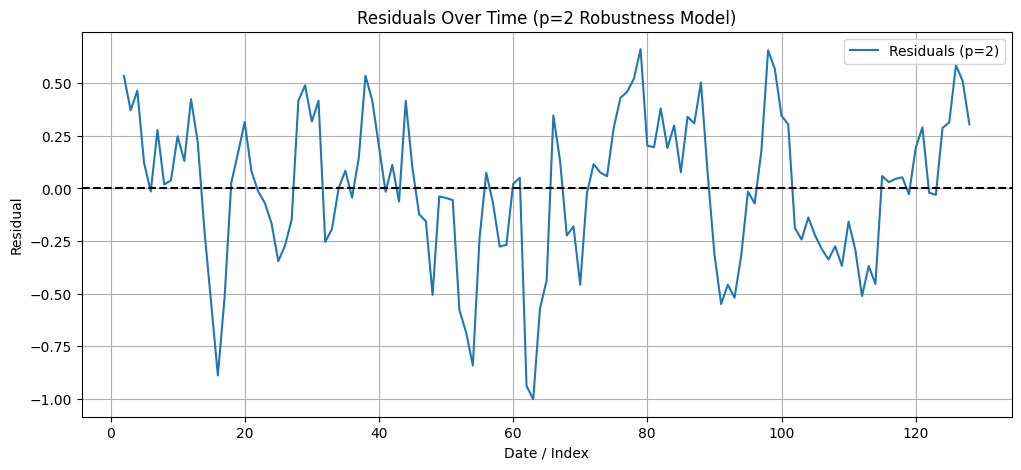

In [ ]:
#Plot residuals over time

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Safely align the x-axis by using the index corresponding to the p=1 dependent variable
plt.plot(
    y_p2.index,
    residuals_p2,
    label="Residuals (p=2)"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--"
)

plt.title("Residuals Over Time (p=2 Robustness Model)")
plt.xlabel("Date / Index")
plt.ylabel("Residual")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#Ljung-Box test for residual autocorrelation

from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_results = acorr_ljungbox(
    residuals_p1,
    lags=[3, 6, 12],
    return_df=True
)

print(ljung_box_results)

       lb_stat     lb_pvalue
3   111.970953  4.131779e-24
6   114.805094  2.006095e-22
12  124.229491  8.841101e-21


In [ ]:
#Ljung-Box test for residual autocorrelation

from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_results = acorr_ljungbox(
    residuals_p2,
    lags=[3, 6, 12],
    return_df=True
)

print(ljung_box_results)

      lb_stat     lb_pvalue
3   83.408749  5.697476e-18
6   84.832485  3.575731e-16
12  94.684798  6.079272e-15


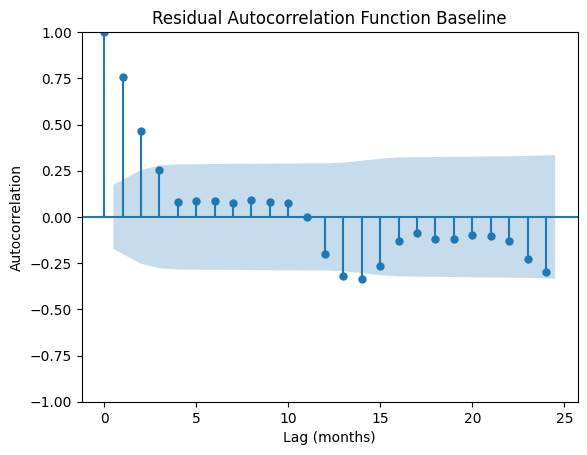

In [ ]:
#Residual autocorrelation function/pattern

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plot_acf(
    model_p1.resid,
    lags=24,
    alpha=0.05
)

plt.title("Residual Autocorrelation Function Baseline")
plt.xlabel("Lag (months)")
plt.ylabel("Autocorrelation")

plt.show()

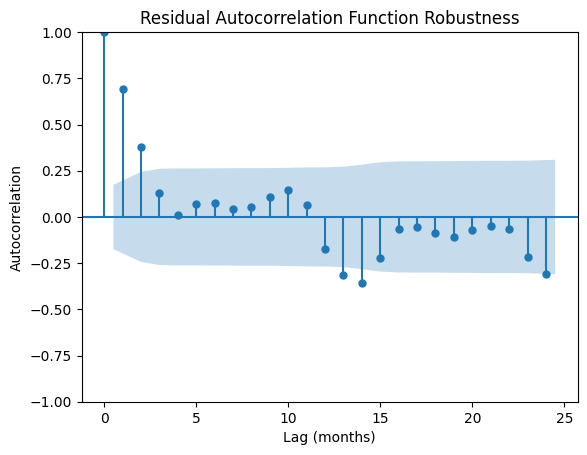

In [ ]:
#Residual autocorrelation function/pattern Robustness

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plot_acf(
    model_p2.resid,
    lags=24,
    alpha=0.05
)

plt.title("Residual Autocorrelation Function Robustness")
plt.xlabel("Lag (months)")
plt.ylabel("Autocorrelation")

plt.show()

In [ ]:
#Extract residuals and fitted values

residuals_p2_hac3 = model_p2_hac3.resid
fitted_values_p2_hac3 = model_p2_hac3.fittedvalues

print("Residual mean:", residuals_p2_hac3.mean())
print("Residual standard deviation:", residuals_p2_hac3.std())
print("Number of observations:", len(residuals_p2_hac3))

Residual mean: -8.741913579725643e-17
Residual standard deviation: 0.35129425019144134
Number of observations: 127


In [ ]:
# 8. Compare key coefficients across HAC bandwidths

comparison = pd.DataFrame({
    "HAC 3": model_p2_hac3.params,
    "SE HAC 3": model_p2_hac3.bse,
    "P-value HAC 3": model_p2_hac3.pvalues,

    "HAC 6": model_p2_hac6.params,
    "SE HAC 6": model_p2_hac6.bse,
    "P-value HAC 6": model_p2_hac6.pvalues,

    "HAC 12": model_p2_hac12.params,
    "SE HAC 12": model_p2_hac12.bse,
    "P-value HAC 12": model_p2_hac12.pvalues
})

print(comparison.loc[
    ["oil_shock", "zar_shock", "joint_shock"]
])

                HAC 3  SE HAC 3  P-value HAC 3     HAC 6  SE HAC 6  \
oil_shock    0.076242  0.046866       0.103783  0.076242  0.048371   
zar_shock    0.042783  0.139774       0.759540  0.042783  0.135991   
joint_shock  0.031255  0.220588       0.887325  0.031255  0.225415   

             P-value HAC 6    HAC 12  SE HAC 12  P-value HAC 12  
oil_shock         0.114983  0.076242   0.044354        0.085629  
zar_shock         0.753066  0.042783   0.134554        0.750516  
joint_shock       0.889722  0.031255   0.244174        0.898146  


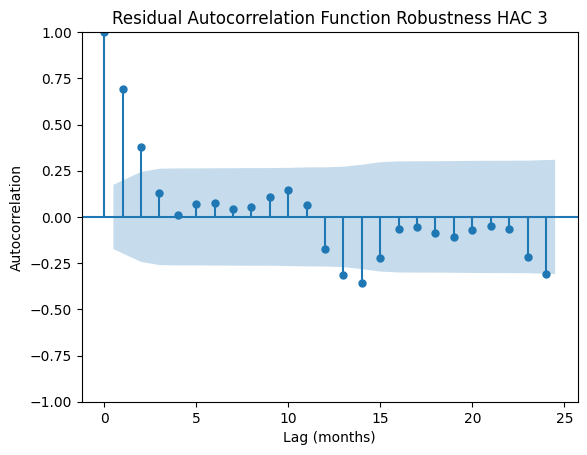

In [ ]:
#Residual autocorrelation function/pattern Robustness

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plot_acf(
    model_p2_hac12.resid,
    lags=24,
    alpha=0.05
)

plt.title("Residual Autocorrelation Function Robustness HAC 3")
plt.xlabel("Lag (months)")
plt.ylabel("Autocorrelation")

plt.show()